# Day 6 – CNN Image Classification: RetailMind AI

This notebook builds and evaluates a CNN image classifier using the Fashion-MNIST dataset. It preprocesses the images, applies data augmentation, trains a CNN, evaluates classification performance, and saves the trained model and results.

## 1. Import libraries and configure paths

In [3]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = Path.cwd()
ARTIFACTS_DIR = BASE_DIR / "artifacts"
OUTPUT_DIR = BASE_DIR / "output"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACTS_DIR / "retailmind_cnn.keras"
METRICS_PATH = OUTPUT_DIR / "evaluation_metrics.json"
CLASS_REPORT_PATH = OUTPUT_DIR / "classification_report.csv"
PREDICTIONS_PATH = OUTPUT_DIR / "test_predictions.csv"

print("TensorFlow version:", tf.__version__)
print("Working directory:", BASE_DIR)

TensorFlow version: 2.22.0-rc0
Working directory: c:\Users\rupam\OneDrive\Desktop\RetailMind Ai\notebooks


## 2. Load the Fashion-MNIST dataset

In [4]:
class_names = [
    "T-shirt_top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle_boot"
]

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. Explore sample images

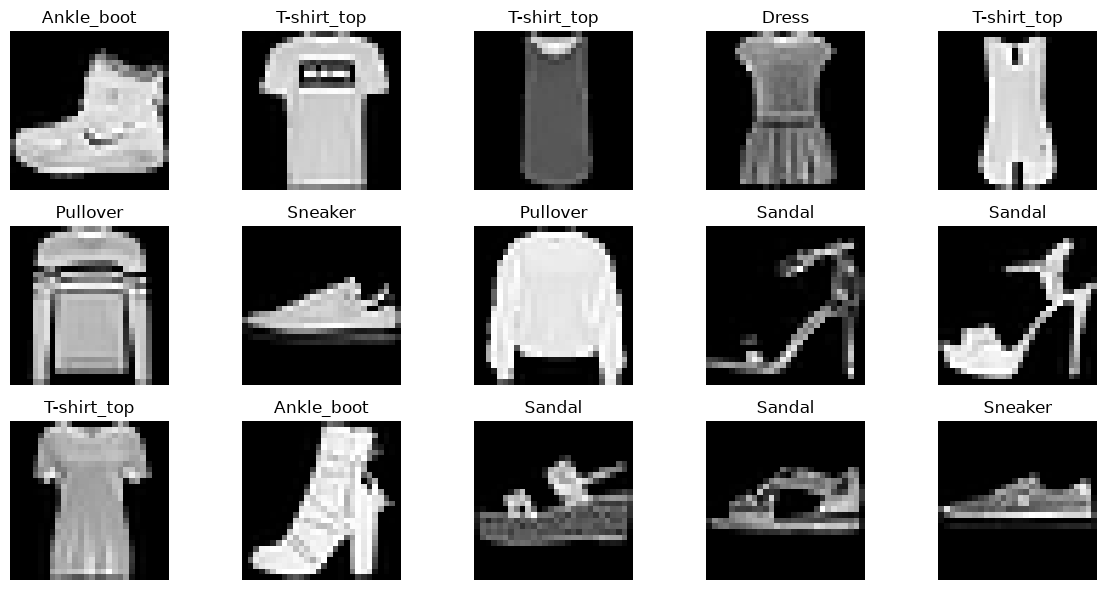

In [5]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Preprocess images

In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

y_train = y_train.astype("int64")
y_test = y_test.astype("int64")

print("Processed training images:", x_train.shape)
print("Processed test images:", x_test.shape)
print("Pixel value range:", float(x_train.min()), "to", float(x_train.max()))

Processed training images: (60000, 28, 28, 1)
Processed test images: (10000, 28, 28, 1)
Pixel value range: 0.0 to 1.0


## 5. Create training and validation datasets

In [7]:
VALIDATION_SIZE = 10000
BATCH_SIZE = 128

x_validation = x_train[-VALIDATION_SIZE:]
y_validation = y_train[-VALIDATION_SIZE:]

x_train_final = x_train[:-VALIDATION_SIZE]
y_train_final = y_train[:-VALIDATION_SIZE]

train_dataset = (
    tf.data.Dataset.from_tensor_slices((x_train_final, y_train_final))
    .shuffle(20000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

validation_dataset = (
    tf.data.Dataset.from_tensor_slices((x_validation, y_validation))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training samples:", len(x_train_final))
print("Validation samples:", len(x_validation))
print("Test samples:", len(x_test))

Training samples: 50000
Validation samples: 10000
Test samples: 10000


## 6. Build the CNN model

In [8]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.10)
    ],
    name="data_augmentation"
)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(28, 28, 1)),
        data_augmentation,
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.35),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.Dense(10, activation="softmax")
    ],
    name="retailmind_cnn"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "retailmind_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,474 (431.54 KB)

 Trainable params: 110,474 (431.54 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the CNN

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True
    )
]

EPOCHS = 15

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15


c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


391/391 ━━━━━━━━━━━━━━━━━━━━ 66s 160ms/step - accuracy: 0.5141 - loss: 1.2573 - val_accuracy: 0.6420 - val_loss: 0.9379 - learning_rate: 0.0010
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 70s 180ms/step - accuracy: 0.6886 - loss: 0.8218 - val_accuracy: 0.7235 - val_loss: 0.7214 - learning_rate: 0.0010
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 59s 151ms/step - accuracy: 0.7301 - loss: 0.7184 - val_accuracy: 0.7626 - val_loss: 0.6341 - learning_rate: 0.0010
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 59s 150ms/step - accuracy: 0.7544 - loss: 0.6605 - val_accuracy: 0.7296 - val_loss: 0.7714 - learning_rate: 0.0010
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 63s 160ms/step - accuracy: 0.7666 - loss: 0.6231 - val_accuracy: 0.7975 - val_loss: 0.5406 - learning_rate: 0.0010
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 64s 164ms/step - accuracy: 0.7814 - loss: 0.5928 - val_accuracy: 0.8000 - val_loss: 0.5378 - learning_rate: 0.0010
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 60s 152ms/step - accuracy: 0.7932 - loss:

## 8. Visualize training performance

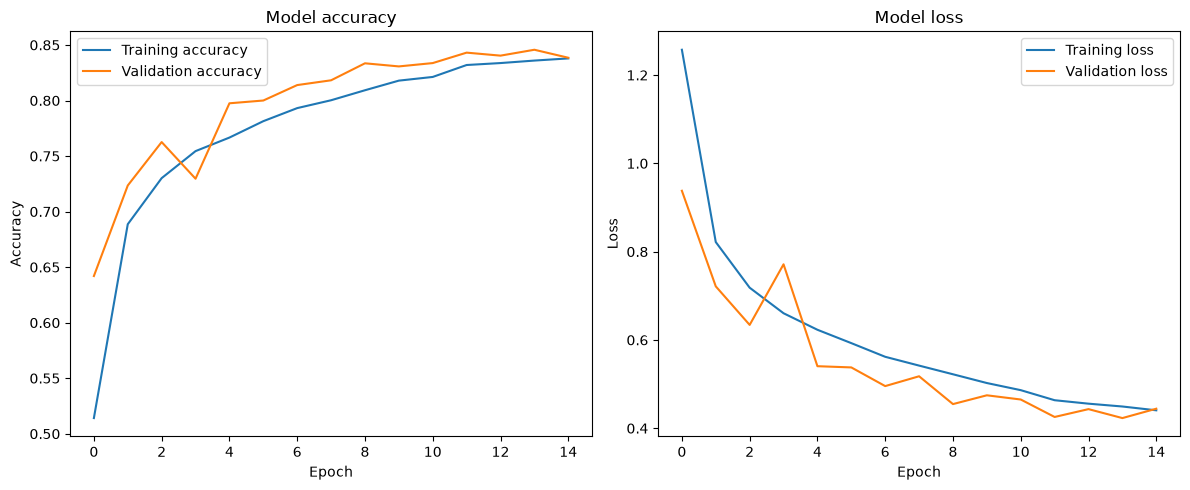

In [10]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model loss")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluate the model on test data

In [11]:
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

probabilities = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)

print("Test loss:", round(float(test_loss), 4))
print("Test accuracy:", round(float(test_accuracy), 4))
print("Accuracy score:", round(float(accuracy), 4))

79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8491 - loss: 0.4364
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step
Test loss: 0.4364
Test accuracy: 0.8491
Accuracy score: 0.8491


## 10. Classification report and per-class metrics

In [12]:
report_dict = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(CLASS_REPORT_PATH, index=True)

display(report_df)

class_accuracy = []

for class_id, class_name in enumerate(class_names):
    mask = y_test == class_id
    class_score = accuracy_score(y_test[mask], y_pred[mask])
    class_accuracy.append({
        "class_name": class_name,
        "accuracy": class_score,
        "samples": int(mask.sum())
    })

class_accuracy_df = pd.DataFrame(class_accuracy)
display(class_accuracy_df)

,precision,recall,f1-score,support
T-shirt_top,0.813953,0.8050,0.809452,1000.0000
Trouser,0.995855,0.9610,0.978117,1000.0000
Pullover,0.773730,0.8070,0.790015,1000.0000
Dress,0.857853,0.8630,0.860419,1000.0000
Coat,0.786830,0.7050,0.743671,1000.0000
Sandal,0.877679,0.9830,0.927358,1000.0000
Shirt,0.593396,0.6290,0.610680,1000.0000
Sneaker,0.947846,0.8360,0.888417,1000.0000
Bag,0.936770,0.9630,0.949704,1000.0000
Ankle_boot,0.928783,0.9390,0.933864,1000.0000


,class_name,accuracy,samples
0,T-shirt_top,0.805,1000
1,Trouser,0.961,1000
2,Pullover,0.807,1000
3,Dress,0.863,1000
4,Coat,0.705,1000
5,Sandal,0.983,1000
6,Shirt,0.629,1000
7,Sneaker,0.836,1000
8,Bag,0.963,1000
9,Ankle_boot,0.939,1000


## 11. Confusion matrix

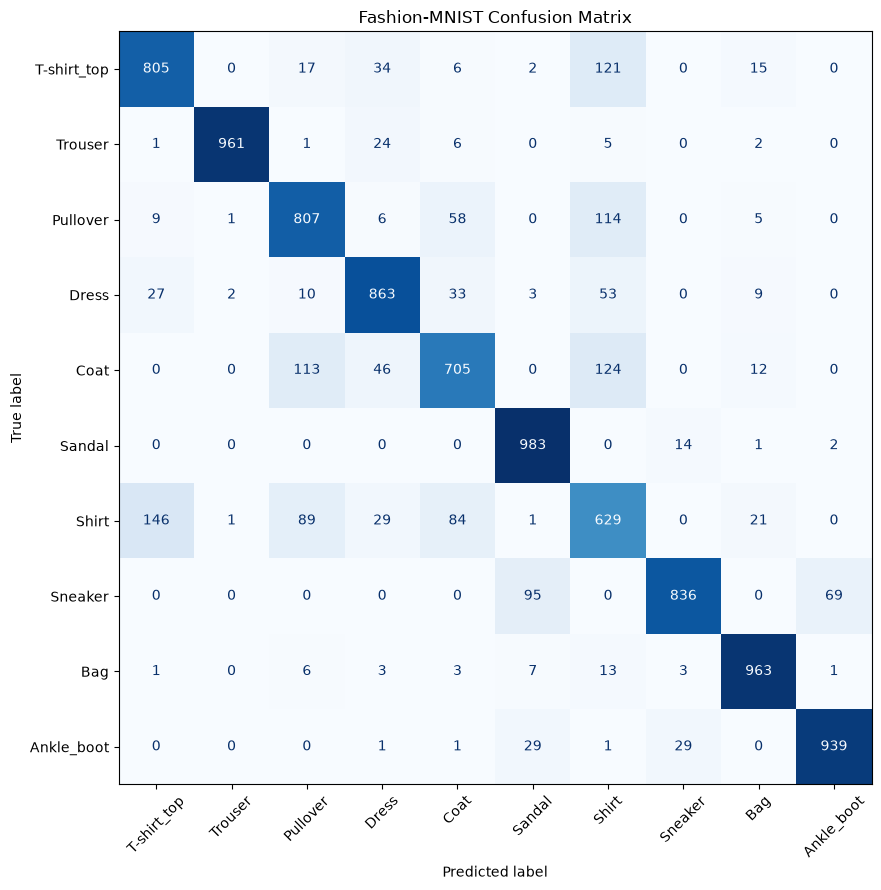

In [13]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(11, 9))
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

## 12. Inspect sample predictions

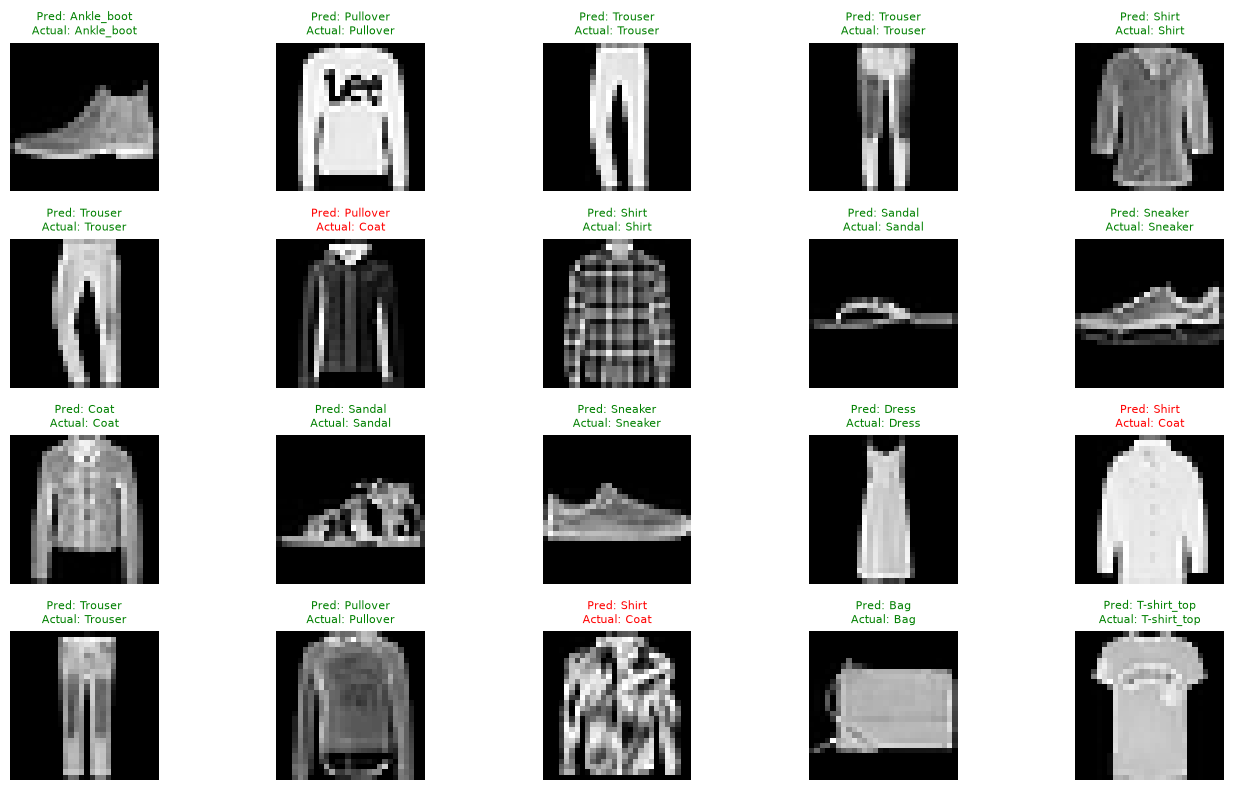

In [14]:
plt.figure(figsize=(14, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    predicted_name = class_names[y_pred[i]]
    actual_name = class_names[y_test[i]]
    title_color = "green" if y_pred[i] == y_test[i] else "red"
    plt.title(
        f"Pred: {predicted_name}\nActual: {actual_name}",
        color=title_color,
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 13. Save model, metrics, and predictions

In [15]:
model.save(MODEL_PATH)

metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "accuracy_score": float(accuracy),
    "epochs_trained": len(history.history["loss"]),
    "class_names": class_names
}

with open(METRICS_PATH, "w") as file:
    json.dump(metrics, file, indent=4)

predictions_df = pd.DataFrame({
    "actual_label": y_test,
    "actual_class": [class_names[i] for i in y_test],
    "predicted_label": y_pred,
    "predicted_class": [class_names[i] for i in y_pred],
    "prediction_confidence": np.max(probabilities, axis=1)
})

predictions_df.to_csv(PREDICTIONS_PATH, index=False)

print("Model saved:", MODEL_PATH)
print("Metrics saved:", METRICS_PATH)
print("Classification report saved:", CLASS_REPORT_PATH)
print("Predictions saved:", PREDICTIONS_PATH)

Model saved: c:\Users\rupam\OneDrive\Desktop\RetailMind Ai\notebooks\artifacts\retailmind_cnn.keras
Metrics saved: c:\Users\rupam\OneDrive\Desktop\RetailMind Ai\notebooks\output\evaluation_metrics.json
Classification report saved: c:\Users\rupam\OneDrive\Desktop\RetailMind Ai\notebooks\output\classification_report.csv
Predictions saved: c:\Users\rupam\OneDrive\Desktop\RetailMind Ai\notebooks\output\test_predictions.csv


## 14. Load the saved model and verify it

In [16]:
loaded_model = tf.keras.models.load_model(MODEL_PATH)

sample_predictions = loaded_model.predict(x_test[:5], verbose=0)
sample_labels = np.argmax(sample_predictions, axis=1)

for index, label in enumerate(sample_labels):
    print(
        "Image:", index,
        "| Predicted class:", class_names[label],
        "| Actual class:", class_names[y_test[index]]
    )

Image: 0 | Predicted class: Ankle_boot | Actual class: Ankle_boot
Image: 1 | Predicted class: Pullover | Actual class: Pullover
Image: 2 | Predicted class: Trouser | Actual class: Trouser
Image: 3 | Predicted class: Trouser | Actual class: Trouser
Image: 4 | Predicted class: Shirt | Actual class: Shirt
